# Tarea 05 — Chatbot Híbrido: Asistente académico de pregrado UNMSM
**Grupo 1** · Ayala Alberca, Sebastian · Gamarra Chavez, Diego Valentino · Reyes Fabian, Jhan Brayan Zamir ·
Jara Espinoza, Angela Lucia

## 1. Introducción
El asistente responde consultas académicas de pregrado de la UNMSM (matrícula, repitencia, reserva,
créditos, grados y títulos, trámites, calendario, bienestar y biblioteca) usando como fuente oficial el
**Reglamento General de Matrícula de Pregrado 2026** (RR N°002642-2026) y la **Ley Universitaria 30220**.

Cada mensaje pasa por cuatro componentes en orden; **el primero que puede responder, responde**:

```
mensaje → 1. Reglas → 3. NLP/ML (intención + entidades) → 2. Recuperación (filtrada por intención) → 4. LLM → respuesta
```

| Componente | Rol |
|---|---|
| **Reglas** | Saludo, ayuda, nombre, despedida y bloqueo de pedidos indebidos |
| **NLP/ML** | Clasifica la intención, extrae datos (facultad, curso, veces) y decide: aceptar, confirmar o pedir un dato |
| **Recuperación** | Busca la pregunta frecuente o el artículo más parecido y lo devuelve tal cual, con su fuente |
| **LLM** | Redacta respuestas a preguntas abiertas usando solo los artículos recuperados, con citas |

Cada respuesta muestra una etiqueta con el componente que la produjo.

### Flujo de un mensaje
Las preguntas de cada paso deciden qué componente responde. Colores: **reglas** (morado), **NLP/ML** (azul), **recuperación** (verde) y **LLM** (rosado).

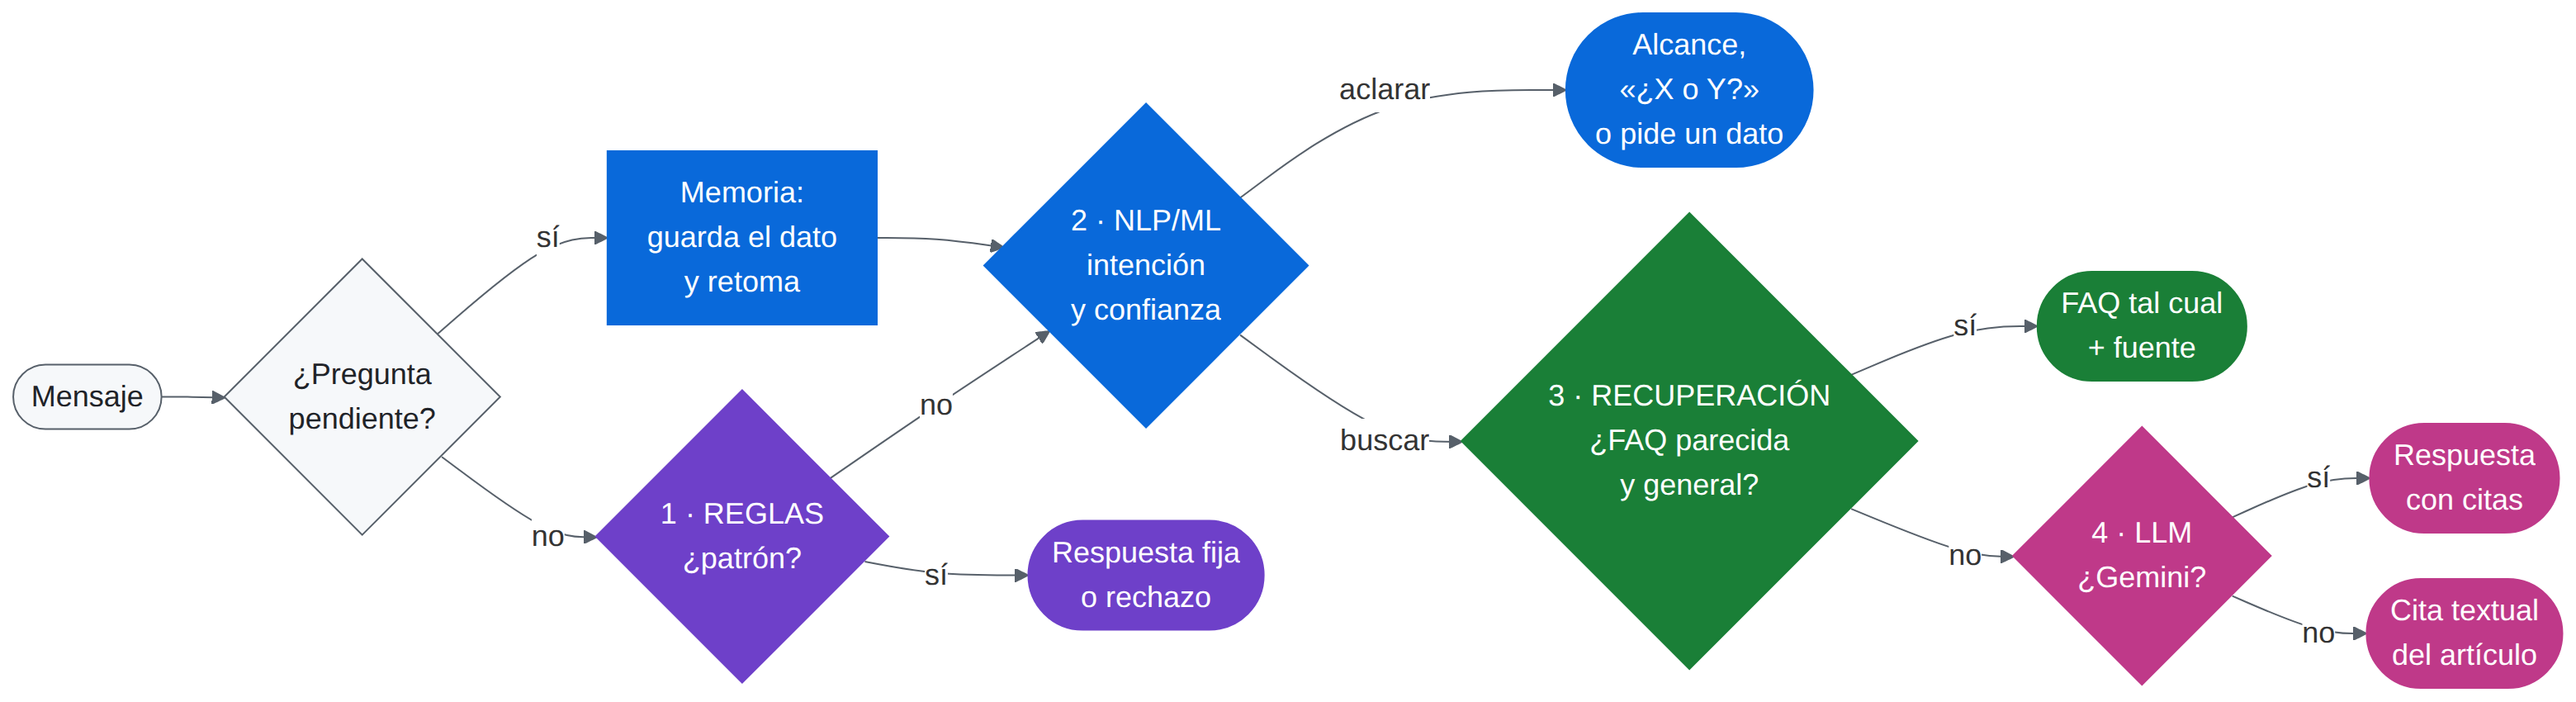

*Diagrama generado desde su definición Mermaid en `src/diagrama.py`.*

## 2. Preparación
El código está en el paquete `src/` (un módulo por componente). La clave de Gemini se lee de la variable de
entorno `GEMINI_API_KEY` (archivo `.env`); sin clave, el chatbot funciona igual y, en lugar de redactar,
cita el artículo del reglamento más relevante.

In [1]:
import inspect
import json
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import HTML, Image, Markdown, display

# El notebook necesita la carpeta del proyecto (task05/, con src/ y data/). Se busca desde la carpeta
# actual hacia arriba, así funciona tanto desde task05/ como desde task05/entregables/.
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "orquestador.py").exists()), None)
if RAIZ is None:
    raise RuntimeError("No se encontró la carpeta del proyecto (src/). Descomprime G1_task05_codigo.zip y abre "
                       "este notebook desde la carpeta task05/ (ver README.md, «Guía rápida»).")
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))
from src import entidades, flujos, llm, politica, recuperacion, reglas
from src.config import DIR_EVALUACION, hay_credencial_online
from src.interfaz import chat, render_html
from src.orquestador import Orquestador

pd.set_option("display.max_colwidth", 110)


def ver_codigo(funcion):
    """Muestra el código de una función del paquete src/."""
    display(Markdown(f"```python\n{inspect.getsource(funcion)}\n```"))


orq = Orquestador.cargar()  # carga reglas, modelo de intención, índice de recuperación y LLM
reporte = json.loads((DIR_EVALUACION / "reporte.json").read_text(encoding="utf-8"))
print("Etapas:", [nombre for nombre, _ in orq.etapas], "· Gemini disponible:", hay_credencial_online())

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Etapas: ['pendiente', 'reglas', 'nlp_ml', 'retrieval', 'llm'] · Gemini disponible: True


## 3. Componente 1 · Basado en reglas
Expresiones regulares definidas en `data/reglas/patrones.yaml`. Primero se evalúan las reglas de
protección (pedidos deshonestos, datos personales de terceros, intentos de cambiar las instrucciones) y
luego las de conversación. Si ninguna coincide, el mensaje pasa al siguiente componente.

In [2]:
motor = reglas.MotorReglas(orq.config)
sesion = orq.nueva_sesion()
ejemplos = ["hola", "me llamo Ana", "ayuda", "pásame las respuestas del examen",
            "¿cuál es la nota de mi compañero Pedro?", "¿cuándo es la matrícula?"]
filas = []
for texto in ejemplos:
    r = motor.evaluar(texto, sesion)
    filas.append({"mensaje": texto, "regla": r.regla if r else "— (pasa al siguiente componente)",
                  "respuesta": r.texto.split("\n")[0][:90] if r else ""})
display(pd.DataFrame(filas))
ver_codigo(reglas.MotorReglas.evaluar)

,mensaje,regla,respuesta
0,hola,saludo,¡Hola! Soy el asistente académico de pregrado de la UNMSM. Puedo orientarte sobre matrícul
1,me llamo Ana,nombre,"¡Mucho gusto, Ana! ¿En qué trámite académico te ayudo?"
2,ayuda,ayuda,"Estos son los temas con los que puedo ayudarte, Ana:"
3,pásame las respuestas del examen,deshonestidad,No puedo ayudarte con eso: va contra la integridad académica de la UNMSM. Sí puedo orienta
4,¿cuál es la nota de mi compañero Pedro?,datos_personales,"No manejo datos personales (códigos, notas, DNI o récord de otras personas). Para tu propi"
5,¿cuándo es la matrícula?,— (pasa al siguiente componente),


```python
    def evaluar(self, texto: str, sesion: Sesion) -> Respuesta | None:
        normalizado = normalizar(texto)
        for regla in self.reglas:
            m = regla.coincide(normalizado, texto)
            if m is None:
                continue
            if regla.nombre == "nombre":
                capturado = m.group(1)
                if capturado in NO_NOMBRES:
                    continue
                sesion.nombre = capturado.capitalize()
            return self._respuesta(regla, sesion)
        return None

```

## 4. Componente 2 · Basado en recuperación de información
La base de conocimiento tiene **41 preguntas frecuentes** y **60 pasajes** del reglamento (uno por
artículo). La consulta se compara por similitud de coseno combinando TF-IDF (palabras) y embeddings
(significado, para reconocer sinónimos). Si la pregunta frecuente más parecida supera el umbral, su
respuesta se devuelve **tal cual**, con la fuente; si no, los artículos más parecidos se pasan al LLM.

In [3]:
indice = recuperacion.Indice.desde_archivos(orq.config)
for pregunta in ["cómo solicito la reserva de mi matrícula", "¿quién ganó el partido de ayer?"]:
    r = indice.respuesta_directa(pregunta)
    print(f"«{pregunta}»")
    print(f"   → {r.texto[:150]}…\n   Fuente: {r.fuentes[0].texto()}\n" if r else "   → sin respuesta (bajo el umbral)\n")
m = reporte["retrieval"]["prueba_pipeline"]
print(f"En 53 preguntas nuevas: respuesta correcta {m['hit_at_1']:.0%} · "
      f"preguntas ajenas correctamente no respondidas {m['no_respuesta_correcta']:.0%}")
ver_codigo(recuperacion.Indice.respuesta_directa)

«cómo solicito la reserva de mi matrícula»
   → La reserva de matrícula te permite postergar tu matrícula de forma fundamentada y acreditada, con opinión favorable del director de tu Escuela Profesi…
   Fuente: Reglamento General de Matrícula Pregrado 2026 (RR N°002642-2026) — Art. 13, lit. h (0.72)

«¿quién ganó el partido de ayer?»
   → sin respuesta (bajo el umbral)

En 53 preguntas nuevas: respuesta correcta 85% · preguntas ajenas correctamente no respondidas 92%


```python
    def respuesta_directa(self, consulta: str, tema: str | None = None) -> Respuesta | None:
        """FAQ más parecida si supera el umbral; su texto se devuelve tal cual, sin generar (FR-020)."""
        mejor = self.mejor_faq(consulta, tema)
        if mejor is None or mejor[1] < self.config.UMBRAL_FAQ:
            return None
        faq, score = mejor
        fuente = Fuente(id=faq.id, documento=faq.documento, ubicacion=faq.ubicacion, score=score)
        texto = faq.texto
        if faq.oficina and faq.oficina not in texto:
            texto += f"\n\nOficina de contacto: {faq.oficina}."
        return Respuesta(texto=texto, componente=Componente.RETRIEVAL, fuentes=[fuente],
                         recordatorio_referencial=recordatorio([faq], faq.texto))

```

## 5. Componente 3 · Basado en NLP / ML
**Intención.** Con 300 frases etiquetadas por el equipo (10 intenciones, incluida jerga como «me jalaron»)
se compararon cinco clasificadores con validación cruzada de 5 folds:
- *Rama léxica:* texto normalizado, sin stopwords y con stemming → TF-IDF → Naive Bayes, Regresión
  Logística o SVM.
- *Rama semántica:* embeddings multilingües (frases con significado parecido quedan cerca) → Regresión
  Logística.
- *Combinación A+B:* promedio de las probabilidades de la mejor rama léxica y la semántica.

La regla de selección se fijó antes de ver los resultados: gana el de mayor F1 promedio, salvo empate
(diferencia menor a una desviación estándar), en cuyo caso gana el más simple.

,candidato,f1_macro_media,f1_macro_std
0,A·NB,0.747,0.037
1,A·LR,0.769,0.037
2,A·SVM,0.774,0.040
3,B·Emb+LR,0.741,0.039
4,A+B promedio,0.841,0.045


Seleccionado: A+B promedio


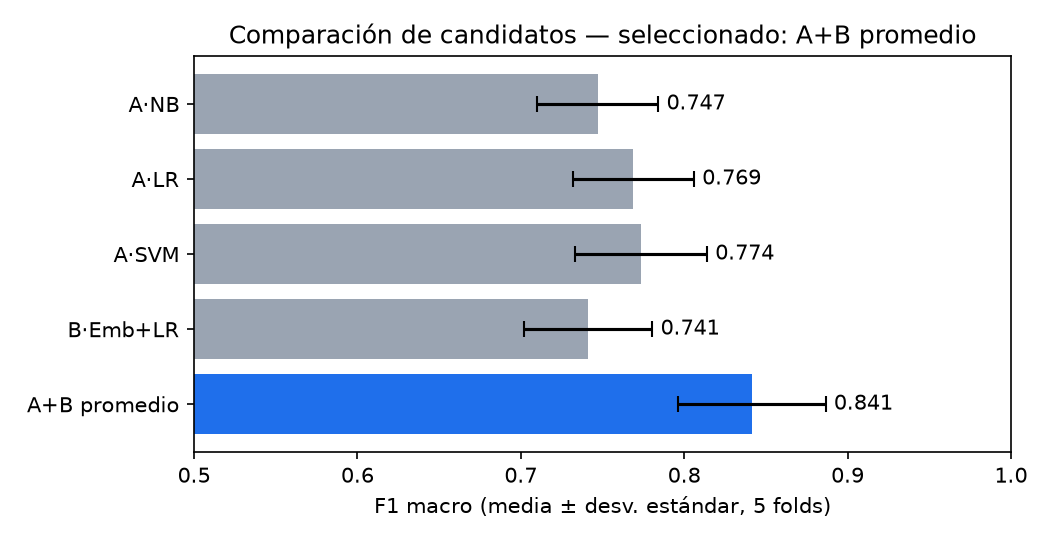

In [4]:
cv = pd.DataFrame(reporte["cv"])[["candidato", "f1_macro_media", "f1_macro_std"]].round(3)
display(cv)
print("Seleccionado:", reporte["seleccion"]["ganador"])
display(Image(filename=str(DIR_EVALUACION / "comparacion_cv.png"), width=650))

**Evaluación final** en 50 frases separadas desde el inicio (nunca usadas para entrenar ni elegir):

Accuracy = 0.84 · F1 macro = 0.83


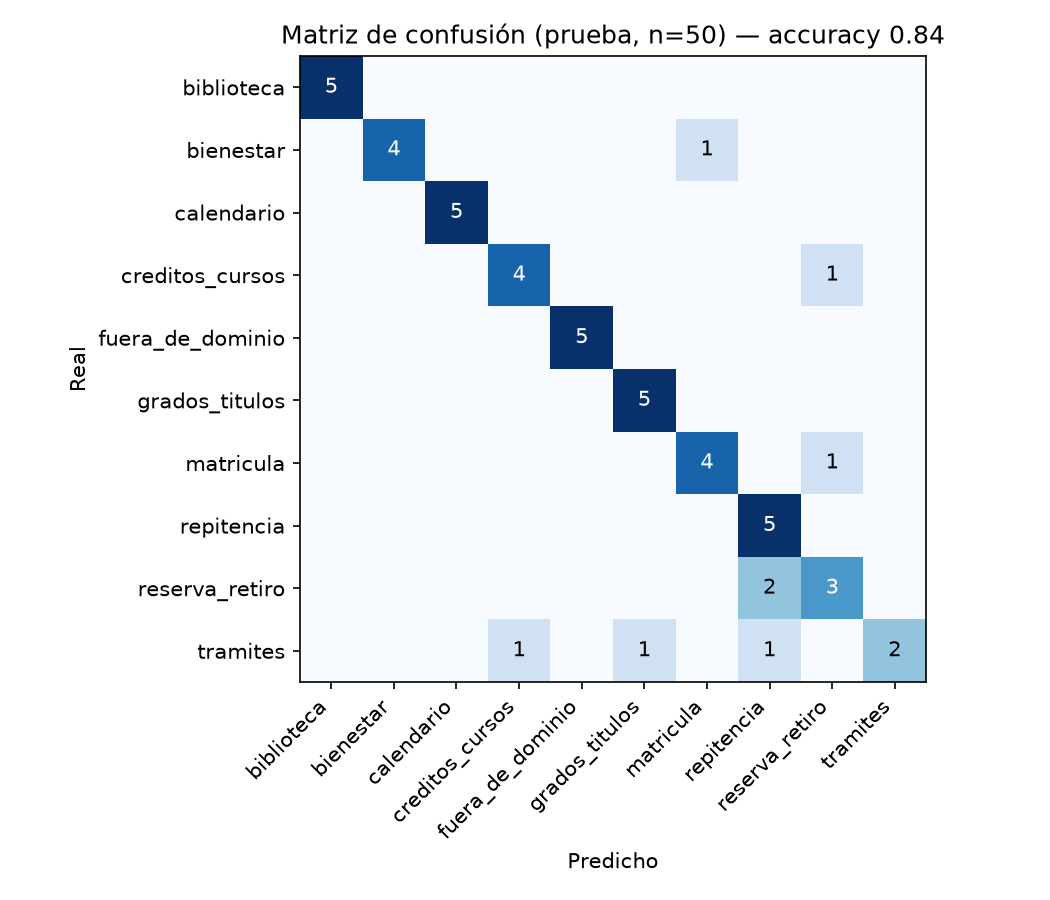

In [5]:
t = reporte["test"]
print(f"Accuracy = {t['accuracy']:.2f} · F1 macro = {t['f1_macro']:.2f}")
display(Image(filename=str(DIR_EVALUACION / "matriz_confusion.png"), width=560))

**Entidades y decisión.** Expresiones regulares, listas del dominio (las 20 facultades con sus siglas) y el
reconocedor de entidades de spaCy extraen los datos del mensaje. Con la confianza del clasificador se
decide: **aceptar** el tema, **confirmar** entre los dos más probables, o **pedir un dato** que falta
(por ejemplo, la facultad), que luego se recuerda durante la conversación.

In [6]:
extractor = entidades.Extractor(orq.config)
mensaje = "Me jalaron Cálculo dos veces, ¿puedo matricularme el próximo ciclo en la FISI?"
print(mensaje, "\n   →", [d.etiqueta() for d in extractor.extraer(mensaje)])
ver_codigo(politica.decidir)

Me jalaron Cálculo dos veces, ¿puedo matricularme el próximo ciclo en la FISI? 
   → ['curso=Cálculo', 'facultad=FISI', 'periodo=proximo_ciclo', 'veces=2']


```python
def decidir(resultado: ResultadoIntencion, detalles: list[Detalle], sesion: Sesion,
            definiciones: dict[str, Intencion], aceptar: float, rechazar: float,
            omitir_requeridos: bool = False) -> Decision:
    b = resultado.banda if resultado.banda == "aceptar" else banda(resultado.confianza, aceptar, rechazar)
    if b == "confirmar" and len(opciones_confirmacion(resultado)) < 2:
        b = "sin_filtro"  # no hay dos temas válidos que ofrecer
    if b == "confirmar":
        opciones = opciones_confirmacion(resultado)
        nombres = [definiciones[t].descripcion.lower() for t in opciones]
        return Decision(banda=b, opciones=opciones,
                        pregunta=f"¿Tu consulta es sobre **{nombres[0]}** o sobre **{nombres[1]}**? "
                                 f"Responde con el tema (o con 1 / 2).")
    if b == "sin_filtro":
        return Decision(banda=b)
    definicion = definiciones[resultado.intencion]
    decision = Decision(banda=b, accion=definicion.accion.value, filtro_tema=resultado.intencion)
    if resultado.intencion == "fuera_de_dominio" or omitir_requeridos:
        return decision
    presentes = {d.tipo: d for d in detalles}
    for requerido in definicion.requeridos:
        detalle = presentes.get(requerido)
        if detalle and detalle.valor:
            continue
        if detalle and detalle.candidatos:  # facultad ambigua ("Ingeniería")
            decision.faltante, decision.opciones = requerido, detalle.candidatos
            decision.pregunta = None  # se arma con los nombres en la etapa
            return decision
        if requerido in sesion.detalles_memoria:
            decision.uso_memoria = True
            continue
        decision.faltante = requerido
        decision.pregunta = definicion.pregunta_detalle.get(requerido, f"¿Me indicas tu {requerido}?")
        return decision
    return decision

```

## 6. Componente 4 · Basado en LLM
Para preguntas abiertas o personales, Gemini recibe los artículos recuperados y la conversación previa, con
instrucciones fijas: responder solo con esos artículos, citarlos y decir «no lo sé» si no alcanzan. Las
citas se verifican contra los artículos enviados. Sin clave o sin conexión, se cita el artículo textual y se
remite a la oficina correspondiente.

In [7]:
sesion = orq.nueva_sesion()
r = orq.responder("Desaprobé dos veces el mismo curso, ¿qué pasa con mi matrícula y qué puedo hacer?", sesion)
display(HTML(render_html(sesion.historial)))
ver_codigo(llm.responder)

```python
def responder(pregunta: str, pasajes: list[EntradaConocimiento], intencion=None, detalles=None, historial=None,
              forzar_offline: bool = False, config: Config | None = None) -> Respuesta:
    config = config or Config()
    usar_online = (not forzar_offline and config.LLM_MODO != "offline" and
                   (config.LLM_MODO == "online" or hay_credencial_online()))
    if usar_online:
        respuesta = _online(pregunta, pasajes, intencion, detalles, historial, config)
        if respuesta is not None:
            return respuesta
    local = _local(pregunta, pasajes, historial, config) if config.LLM_LOCAL_MODELO else None
    return local or _extractivo(pasajes)

```

## 7. Chatbot híbrido
### 7.1 Cuatro casos de uso completos
Cada caso es la conversación de un estudiante de principio a fin, en la que intervienen varios componentes.
Cada turno se verifica contra el comportamiento esperado (`data/flujos.yaml`).

In [8]:
for id_, turnos in flujos.ejecutar_todos(orq).items():
    datos = flujos.flujo(id_, orq.config)
    display(Markdown(f"**{flujos.titulo(datos)}** — {datos['historia']}"))
    display(HTML(render_html(turnos, numerar=True)))
    errores = flujos.verificar(id_, turnos, orq.config)
    print("✅ comportamiento esperado" if not errores else "\n".join(errores))

**Caso 1 — Ana se matricula por primera vez** — Ana, cachimba de Ingeniería de Sistemas, pregunta hasta cuándo puede matricularse y cómo hacerlo por internet.

✅ comportamiento esperado


**Caso 2 — Luis desaprobó Cálculo dos veces** — Luis quiere saber si puede volver a matricularse, qué pasa si desaprueba otra vez y qué hace si no dictan el curso.

✅ comportamiento esperado


**Caso 3 — María necesita dejar de estudiar un año** — María tiene que trabajar: pregunta cómo pausar sus estudios, cómo regresar y qué pasa si no vuelve a tiempo.

✅ comportamiento esperado


**Caso 4 — Pedro está por egresar** — Pedro terminó sus créditos: confirma si ya es egresado y pregunta por el bachiller y el título.

✅ comportamiento esperado


### 7.2 Chat interactivo
Escribe en la caja y presiona Enter. El chat necesita un kernel en ejecución: si este notebook se abre ya
ejecutado (sin kernel), abajo se ve una conversación de ejemplo.

In [9]:
sesion = orq.nueva_sesion()
for texto in ["hola", "¿hasta cuándo es la matrícula?", "Sistemas"]:
    orq.responder(texto, sesion)
display(HTML(render_html(sesion.historial, "Conversación de ejemplo")))
chat(orq)

### 7.3 Conclusiones
- **Reglas:** respuestas inmediatas y predecibles; bloquean pedidos indebidos antes que cualquier otro
  componente.
- **Recuperación:** con el filtro de intención acierta el 85 % de preguntas nuevas y siempre muestra la
  fuente; no inventa contenido.
- **NLP/ML:** combinar TF-IDF y embeddings supera a cada técnica por separado (F1 0.84 en validación cruzada;
  en la prueba F1 0.83 y accuracy 0.84). Cuando duda, pregunta en vez de equivocarse.
- **LLM:** redacta respuestas con citas a partir del reglamento; en la revisión de 16 respuestas no afirmó nada
  fuera de las fuentes.
- **Híbrido:** cada componente aporta donde es más fuerte: reglas para lo fijo, recuperación para lo
  verificable, NLP/ML para entender y decidir, LLM para redactar.